# GPU rental market: overview

Daily rental prices for data-centre GPUs, in $ per GPU-hour, from the aggregated data in `data/processed/`:

- **Price index** (`composite_index`): the market price level after removing each provider's persistent premium or discount; unaffected by providers entering or leaving the data. Used for pricing and backtests.
- **Average posted price** (`composite_level`): a trimmed average of the providers quoted that day. It jumps when the mix of providers changes.
- **Ornn transacted index**: prices from actual trades (free tier: H100 history from late June; today's value for other GPUs).

All are posted *list* prices except Ornn. See `src/compute_options/data/aggregate.py` for the method.

## Parameters

In [1]:
# None = the data-centre GPUs with 60+ days of history (up to 8, one colour each),
# or a list, e.g. ["H100_SXM", "H200", "B200"]
GPUS = None

# Rebase date for the relative-performance chart. None = earliest date.
# GPUs whose data starts later are rebased at their own first day (dashed).
REBASE_FROM = "2026-03-01"

VOL_WINDOW_DAYS = 60  # trailing window for rolling volatility

In [2]:
%matplotlib inline
import pandas as pd

from compute_options.analytics import market_viz as mv

mv.apply_style()
pd.set_option("display.width", 160)
data = mv.MarketData()

gpus = GPUS or data.gpus(min_days=60)
print(f"{len(gpus)} GPUs, data to {data.index.index[-1].date()}")

6 GPUs, data to 2026-09-26


## Latest prices

Price index today, the average posted price, Ornn's transacted price, changes over 1 and 3 months and since the start of each GPU's data (note the different start dates), and annualised volatility of weekly changes. The table lists every GPU with 60+ days of history; the charts show the data-centre GPUs.

In [3]:
mv.summary_table(data, data.gpus(min_days=60, charted_only=False))

,index ($/GPU-hr),avg posted ($/GPU-hr),Ornn transacted,1M,3M,since start,"vol (weekly, ann.)",providers today,history from
GPU,,,,,,,,,
H100_SXM,$3.76,$3.64,$2.54,+0.7%,+13.5%,+15.7%,19%,23,2026-02-11
H200,$4.53,$4.81,$4.78,+2.5%,+14.5%,+17.6%,14%,16,2026-02-11
B200,$7.02,$6.85,$8.04,+2.3%,+9.5%,+27.7%,18%,12,2026-02-11
A100_SXM_80GB,$2.26,$2.21,$0.95,+0.2%,+11.6%,+6.8%,18%,17,2026-02-11
B300,$8.95,$8.22,-,+2.1%,n/a,+5.1%,17%,10,2026-07-19
L40S,$1.50,$1.48,-,+4.5%,+12.2%,+2.0%,22%,13,2026-02-11
A100_PCIE_80GB,$1.87,$1.86,-,-2.1%,+2.5%,+2.5%,14%,5,2026-02-11
A100_SXM_40GB,$2.25,$2.23,-,-0.1%,+15.0%,+16.0%,21%,7,2026-02-11
L4,$0.77,$0.77,-,-0.4%,n/a,+2.8%,6%,6,2026-07-20


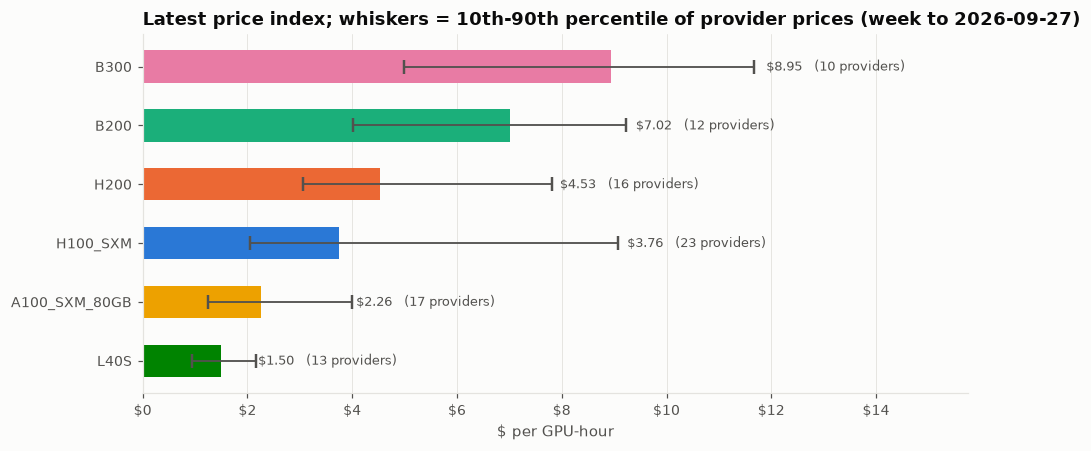

In [4]:
mv.plot_latest_prices(data, gpus);

## Price history

Each GPU in its own panel, in $ per GPU-hour. The coloured line is the price index; grey is the average posted price (note its jumps when providers enter or leave); dashed black is Ornn's transacted index where it has history.

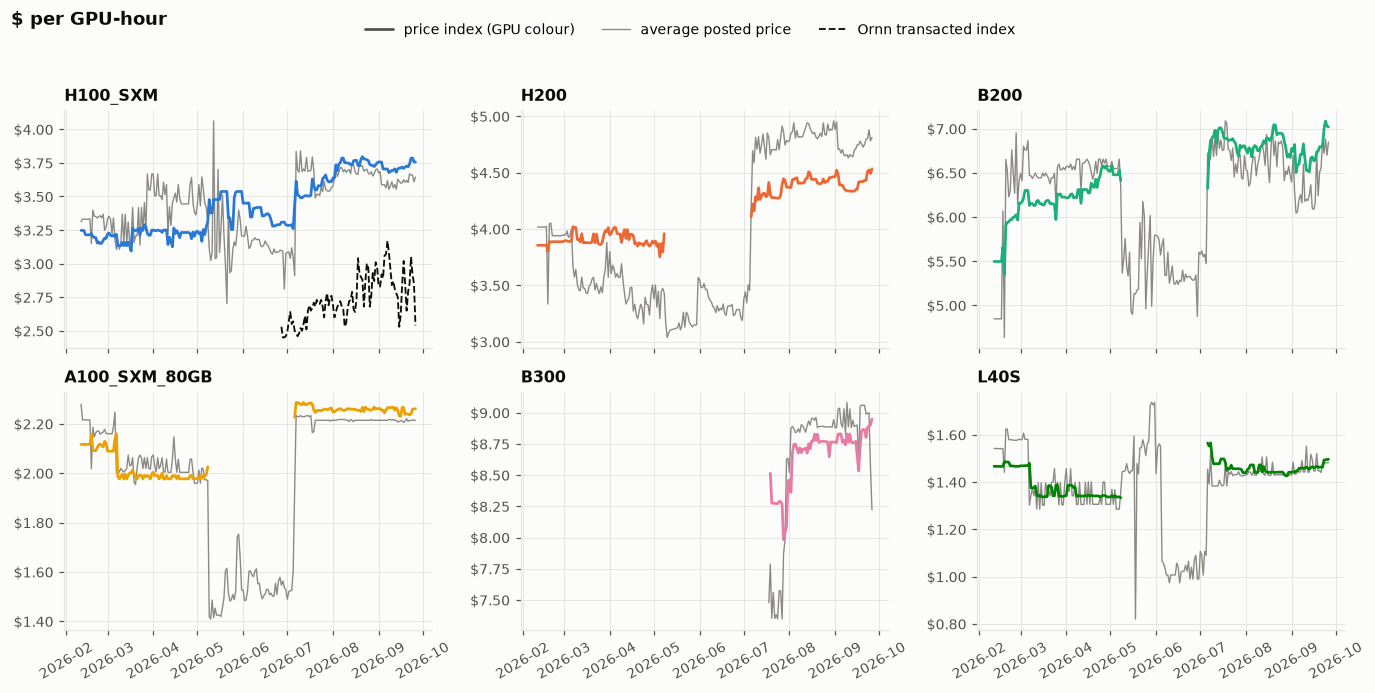

In [5]:
mv.plot_price_panels(data, gpus);

## Relative performance

All GPUs on one axis, rebased to 100, so their moves can be compared despite very different price levels.

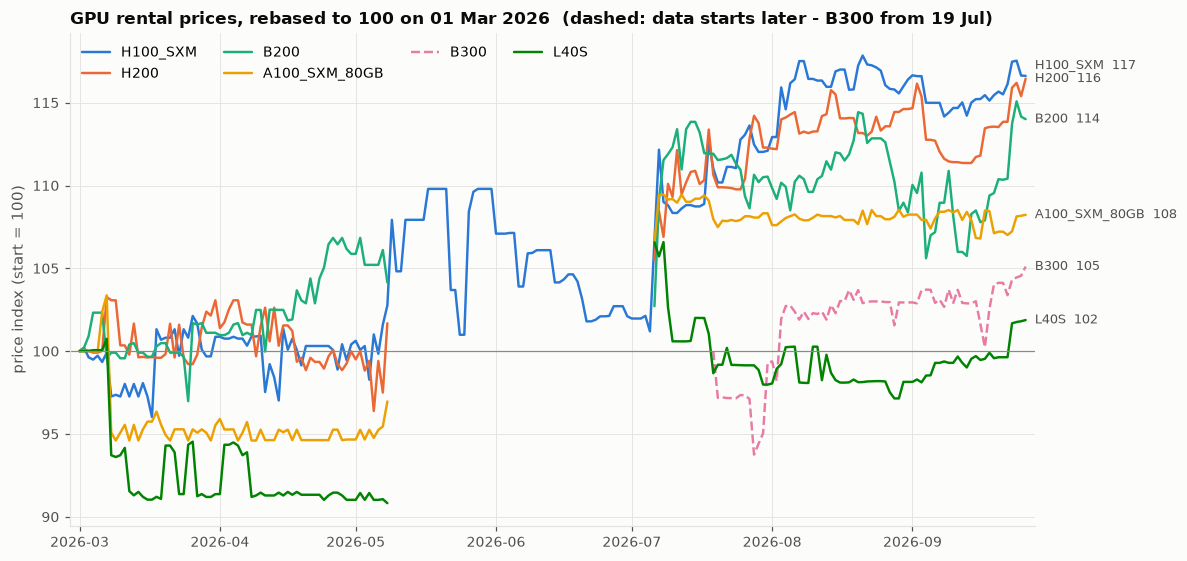

In [6]:
mv.plot_indexed(data, gpus, REBASE_FROM);

## Volatility

Annualised volatility of weekly price changes over a trailing window. Posted prices move in steps, so volatility comes in bursts when providers reprice.

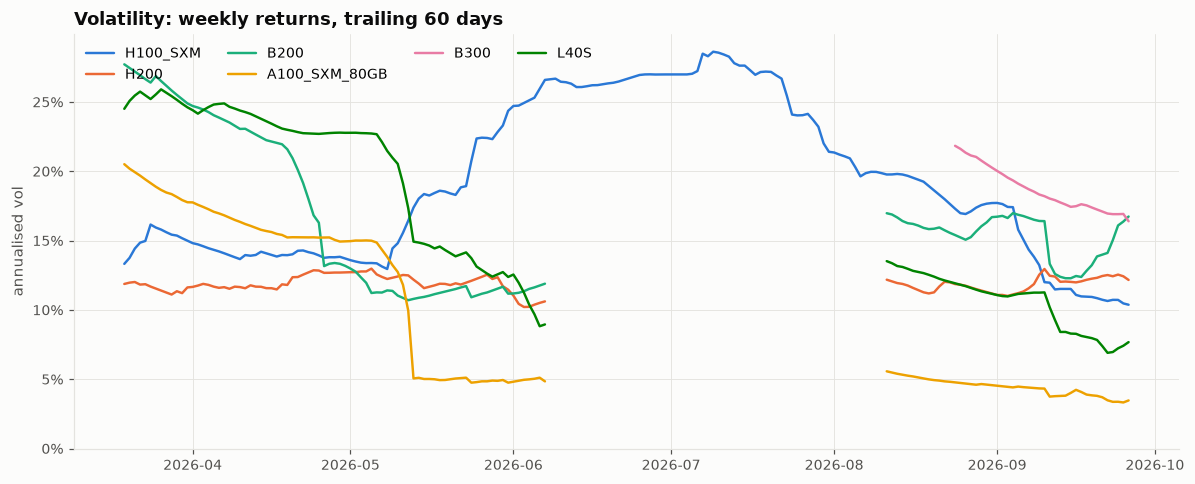

In [7]:
mv.plot_rolling_vol(data, gpus, VOL_WINDOW_DAYS);

## Posted vs transacted

How far the average posted list price sits above Ornn's transaction-based index. Ornn's free tier only has history for H100.

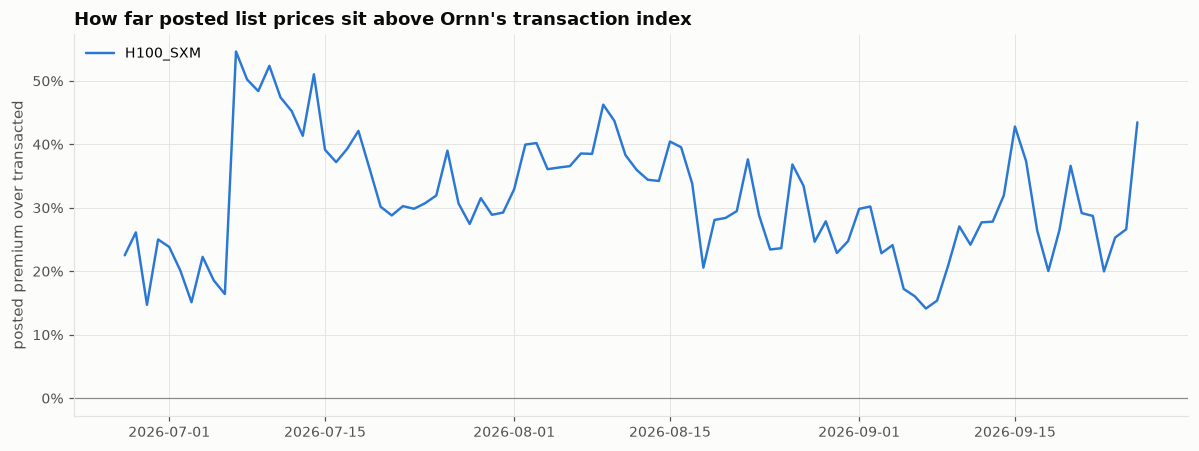

In [8]:
mv.plot_premium_to_ornn(data, gpus);

## Data coverage

How many providers were quoted each day. Thin coverage (light cells) makes the index noisier; days with fewer than 5 providers are left out of the index. Most history before July comes from a single scraper.

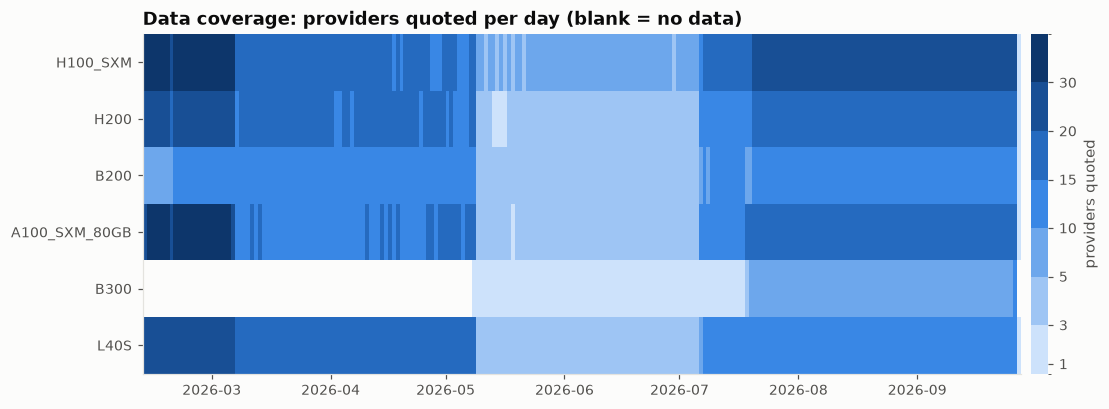

In [9]:
mv.plot_coverage(data, gpus);